# Do listeners reward harmonic complexity? Chord complexity and popularity in jazz standards (RQ2)

**Author:** Calvin Pan
**Date created:** October 10, 2026
**Date last modified:** October 10, 2026

### ⚠️ STATUS: INCOMPLETE (work in progress)
- **Done:** JazzStandards.com outcome (Section 2), with preliminary regressions in Section 4.
- **Not done yet:** Last.fm listener and play counts (Section 3). This needs a Last.fm API key and an overnight run, so Table 4 currently only has the JazzStandards.com columns.
- **Not done yet:** the within-tune "Autumn Leaves" version (Section 5). This needs the Last.fm data plus hand-coding the chords of each recording.

All results below are preliminary.

---

This is a fun side project I started alongside my Impact Evaluations class (LPPA 7220) in UVA Batten's Master of Public Policy program. It's the second half of the project. The first half, `jazzchords_pan_rq1_complexity.ipynb`, measures how complex each tune's harmony is.

**RQ2 (associational):** Are jazz standards with more complex harmony recorded more often by jazz musicians, or listened to more?

I use the five complexity measures from the RQ1 notebook: vocabulary tier (1–5), pitch-class count, dissonance (Huron 1994), surprisal (following [Cheung et al. 2019](https://doi.org/10.1016/j.cub.2019.09.067)), and tonal complexity (Weiß & Müller 2014). Each is averaged to the tune level.

**Data sources:**
- Tune-level complexity measures from `jazzchords_pan_rq1_complexity.ipynb`, built from the [iRb Corpus of Jazz Standards](https://zenodo.org/records/3546040) (CC BY 4.0).
- [JazzStandards.com](https://www.jazzstandards.com/compositions/index.htm) rankings of the top 1,000 standards. The [ranking](https://www.jazzstandards.com/overview.ranking.htm) is based on how many different jazz artists have recorded each tune on CD (the site only publishes the rank, not the raw counts).
- [Last.fm API](https://www.last.fm/api) listener and play counts (needs a free API key, see Section 3).

### NOTE: Run the RQ1 notebook first, and Section 3 needs a Last.fm API key.

This notebook loads `output/rq1_tune_level_complexity.csv` and `output/rq1_chord_transition_counts.csv`, which `jazzchords_pan_rq1_complexity.ipynb` saves.

Get a free Last.fm key at https://www.last.fm/api/account/create and paste it into the `LASTFM_API_KEY` cell in Section 3. Everything except Section 3 and the data-collection part of Section 5 runs without one.

Last.fm's [API terms](https://www.last.fm/api/tos) ask you to "drop them a line" before using the API for research/academic purposes, and to only use the data non-commercially. I also shouldn't push the Last.fm data to a public GitHub repo, so `rawdata/` should go in `.gitignore`.

Folder structure:

challenge2_jazzchords/
                    -- jazzchords_pan_rq1_complexity.ipynb (run first)
                    -- jazzchords_pan_rq2_popularity.ipynb (this notebook)
                    -- rawdata (JazzStandards ranks, Last.fm cache, Autumn Leaves coding sheet)
                    -- output (tables + figures; also where the RQ1 files are loaded from)  

### 0. Install packages

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
import re
import os
import time
import html
import unicodedata
import urllib.parse
import requests
from itertools import combinations

### 1. Load the tune-level complexity measures from the RQ1 notebook

In [2]:
# Set directories
dir = "/Users/calvin/Library/Mobile Documents/com~apple~CloudDocs/Documents/Calvin/UVA/2026-27/LPPA_7220_Impact_Evals/python/impactevals/challenge2_jazzchords/"
rawdata_dir = dir + "rawdata/"
output_dir = dir + "output/"

os.makedirs(rawdata_dir, exist_ok=True)
os.makedirs(output_dir, exist_ok=True)

In [3]:
# Load the tune-level measures saved at the end of the RQ1 notebook
tune_level = pd.read_csv(output_dir + "rq1_tune_level_complexity.csv")
tune_level["era"] = pd.Categorical(tune_level["era"], categories=["Pre-1930", "1930s", "1940s", "1950s", "1960s", "1970+"], ordered=True)

measures = ["tier", "n_pcs", "dissonance", "surprisal", "tonal_complexity"]
measure_labels = {"tier": "Vocabulary tier (1–5)",
                  "n_pcs": "Pitch classes",
                  "dissonance": "Dissonance",
                  "surprisal": "Surprisal (bits)",
                  "tonal_complexity": "Tonal complexity"}

# Load the chord-transition counts (used to score surprisal for the Autumn Leaves recordings in Section 5)
# keep_default_na=False keeps "" (a plain major triad's quality) from being read in as missing
transition_counts = pd.read_csv(output_dir + "rq1_chord_transition_counts.csv", keep_default_na=False)
pair_all = transition_counts.set_index(["context", "outcome"])["n"]
ctx_all = transition_counts.groupby("context")["n"].sum()
V = transition_counts["outcome"].nunique()
K = 0.1   # Same smoothing constant as RQ1

# Checks
print(str(len(tune_level)) + " tunes, " + str(len(pair_all)) + " chord transitions")   # Should be 1186 tunes
tune_level.head()

1186 tunes, 2733 chord transitions


,tune_id,title,composer,year,key,meter,n_changes,era,minor_key,key_mode,...,tier,n_pcs,dissonance,surprisal,tonal_complexity,z_tier,z_n_pcs,z_dissonance,z_surprisal,z_tonal_complexity
0,26-2,26-2,"Coltrane, John",1959,F,4/4,58,1950s,0,Major key,...,3.000000,4.000000,-0.380681,3.962501,0.924056,-0.713355,-0.418898,0.170859,-0.641483,2.095865
1,500mileshigh,500 Miles High,"Corea, Chick",1972,e,4/4,22,1970+,1,Minor key,...,3.454545,4.136364,-0.451574,6.299225,0.843279,0.351668,0.121751,-0.962851,0.792976,0.844555
2,502blues,502 Blues,"Rowles, Jimmy",1966,a,3/4,33,1960s,1,Minor key,...,3.727273,4.242424,-0.364181,7.592469,0.910137,0.990682,0.542256,0.434727,1.586867,1.880246
3,52ndstreettheme,52nd Street Theme,"Monk, Thelonious",1948,C,4/4,48,1940s,0,Major key,...,2.437500,3.708333,-0.537545,3.884081,0.650942,-2.031321,-1.575287,-2.337679,-0.689624,-2.134964
4,920special,9.20 Special,"Warren, Earl",1945,C,4/4,50,1940s,0,Major key,...,3.520000,4.140000,-0.352158,8.123443,0.795024,0.505032,0.136169,0.626993,1.912820,0.097030


### 2. Outcome #1: how often is each tune recorded? (JazzStandards.com rank)
JazzStandards.com ranks the top 1,000 standards by how many different jazz artists have recorded each one on CD. It only publishes the **rank**, not the counts, so I use two outcomes:
1. `js_top1000`: 1 if the tune is in the top 1,000 at all (defined for all 1,186 iRb tunes).
2. `js_pop` = −log(rank): higher = recorded more often (only defined for ranked tunes).

The site's robots.txt allows crawling, and this is only 10 pages. I add a 1-second pause between requests anyway and save the result, so it only gets scraped once.

In [4]:
js_path = rawdata_dir + "jazzstandards_ranks.csv"

if not os.path.exists(js_path):
    js_rows = []
    for page in range(1, 11):
        url = "https://www.jazzstandards.com/compositions/index.htm" if page == 1 else "https://www.jazzstandards.com/compositions/index" + str(page) + ".htm"
        r = requests.get(url, headers={"User-Agent": "Academic research script (UVA LPPA 7220 class project)"}, timeout=30)
        r.encoding = "windows-1252"
        # Each row looks like: <td>rank</td><td>year</td><td><a href="...">Title</a>
        for rank, year, href, title in re.findall(r'<tr class="JSContentsLine"><td align="right">(\d+)<br></td><td align="center">([^<]*)<br></td><td>&nbsp;<a href="([^"]+)">(.*?)</a>', r.text):
            js_rows.append({"js_rank": int(rank), "js_year": year, "js_title": html.unescape(title), "js_url": href})
        time.sleep(1)   # Be polite
    pd.DataFrame(js_rows).to_csv(js_path, index=False)

js = pd.read_csv(js_path)
print(str(len(js)) + " ranked standards")   # Should be 1000
js.head()

1000 ranked standards


,js_rank,js_year,js_url,js_title
0,1,1930,https://www.jazzstandards.com/compositions-0/b...,Body and Soul
1,2,1939,https://www.jazzstandards.com/compositions-0/a...,All the Things You Are
2,3,1935,https://www.jazzstandards.com/compositions-0/s...,Summertime
3,4,1944,https://www.jazzstandards.com/compositions-0/r...,'Round Midnight
4,5,1935,https://www.jazzstandards.com/compositions-0/i...,I Can't Get Started (with You)


**Matching titles.** iRb and JazzStandards.com spell titles differently ("Surrey With The Fringe On The Top" vs. "The Surrey with the Fringe on Top", "Best Thing For You Is Me, The", "Makin' Whoopee" vs. "Making Whoopee"). I standardize both (lowercase, drop punctuation and parentheses, drop a leading "The/A", treat "-in'" as "-ing"). I checked the remaining near-misses by hand against year and composer, and the true matches are in `MANUAL_MATCHES`.

I deliberately don't use automatic fuzzy matching, because it produces false matches like "Blue Monk" → "Blue Moon" and "Night Train" → "Freight Train."

In [5]:
def title_key(title):
    t = unicodedata.normalize("NFKD", str(title)).encode("ascii", "ignore").decode()
    t = t.lower().replace("&", "and")
    t = re.sub(r"\(.*?\)|\[.*?\]", "", t)       # Drop parentheses/brackets
    t = re.sub(r"\b(\w+)in'", r"\1ing", t)       # Makin' → making
    t = re.sub(r"\b'?till?\b", "til", t)         # Till / 'til / til → til
    t = re.sub(r"[^a-z0-9 ]", "", t)             # Drop punctuation
    t = re.sub(r"^(the|a|an) ", "", t.strip())   # Drop leading article
    return t.replace(" ", "")

# iRb writes "Best Thing For You Is Me, The" → move the article to the front
tune_level["title_clean"] = tune_level["title"].str.replace(r"^(.*), (The|A|An)$", r"\2 \1", regex=True)

# Hand-checked matches (iRb title → JazzStandards.com title)
MANUAL_MATCHES = {
    "Our Love is Here to Stay": "Love Is Here to Stay",
    "Mac The Knife": "Mack the Knife",
    "In A Mellow Tone (In A Mellotone)": "In a Mellotone",
    "I Can't Believe...You're In Love...": "I Can't Believe That You're in Love with Me",
    "Milestones-New": "Milestones",                       # The 1958 modal "Milestones" (JazzStandards lists it as 1958)
    "Surrey With The Fringe On The Top": "The Surrey with the Fringe on Top",
    "Bess You Is My Woman": "Bess, You Is My Woman Now",
    "Tisket A Tasket, A": "A-Tisket, A-Tasket",
    "Nandis": "Nardis",                                   # Typo in iRb; same year (1959)
    "I'm Through With Love": "I'm Thru with Love",
    "I Get Along Without You": "I Get Along Without You Very Well",
    "Jumpin With Symphony Sid": "Jumpin' with Symphony Sid",
    "You Brought A New Kind Of Love": "You Brought a New Kind of Love to Me",
    "Everything I Love": "Ev'rything I Love",
    "Best Thing For You Is Me, The": "The Best Thing for You",
    "Is You Is Or Is You Ain't (Ma' Baby)": "Is You Is or Is You Ain't My Baby?",
    "What Are You Doing New Years": "What Are You Doing New Year's Eve?",
}

tune_level["match_key"] = tune_level["title"].map(MANUAL_MATCHES).fillna(tune_level["title_clean"]).apply(title_key)
js["match_key"] = js["js_title"].apply(title_key)

# Drop the merge columns first if this cell is re-run
tune_level = tune_level.drop(columns=["js_rank", "js_title", "js_year", "js_url"], errors="ignore")
tune_level = tune_level.merge(js[["match_key", "js_rank", "js_title"]], on="match_key", how="left")
tune_level["js_top1000"] = tune_level["js_rank"].notna().astype(int)
tune_level["js_pop"] = -np.log(tune_level["js_rank"])

# Checks
print(str(tune_level["js_top1000"].sum()) + " of " + str(len(tune_level)) + " iRb tunes are in the JazzStandards.com top 1,000")

657 of 1186 iRb tunes are in the JazzStandards.com top 1,000


### 3. Outcome #2: total listeners and plays across all recordings of a tune (Last.fm)
A tune like "Autumn Leaves" has hundreds of recordings, so I want *total* listening across all of them. The pipeline for each tune:

1. **`track.search`** on the tune's title, up to `MAX_PAGES` pages of results. Each result is one recording, and Last.fm gives its listener count directly in the search results.
2. **Keep only recordings whose title actually matches** (after stripping "- Remastered 1999", "(Live)", etc.) and that have at least `MIN_LISTENERS` listeners.
3. **`artist.getInfo`** on each artist to get their tags, so I can **keep only jazz artists**. Without this filter, "Autumn Leaves" also picks up Ed Sheeran's unrelated song with the same name. I also save each artist's total listeners as a control for fame.
4. **`track.getInfo`** for play counts. This is one call per recording, which is the slow part, so I only get plays for each tune's `PLAYCOUNT_TOP_N` most-listened recordings. Listening is very top-heavy, so the top recordings make up most of the plays.

Total listeners double-counts people who listened to more than one version. That's fine here, since the question is about overall listening to the tune, not unique people.

**Speed.** Last.fm doesn't publish an exact rate limit in its current terms, but the commonly cited limit is about 5 requests per second. I throttle to 4 per second (`SECONDS_BETWEEN_CALLS = 0.25`). Every response is saved to `rawdata/lastfm/` as it comes in, so the run can be stopped and restarted without redoing calls (and Last.fm's terms require caching anyway).

In [6]:
# >>> Paste your Last.fm API key here <<<
LASTFM_API_KEY = ""

In [7]:
# Settings
MAX_PAGES = 4                 # Up to 4 pages x 50 results = the top 200 search results per tune
RESULTS_PER_PAGE = 50
MIN_LISTENERS = 100           # Ignore recordings with fewer than 100 listeners (mostly noise/duplicates)
PLAYCOUNT_TOP_N = 20          # Get play counts for each tune's top 20 jazz recordings
SECONDS_BETWEEN_CALLS = 0.25  # Max 4 calls per second
JAZZ_TAG_WORDS = ["jazz", "bop", "swing", "bossa", "big band", "crooner", "standards", "dixieland", "ragtime"]

lastfm_dir = rawdata_dir + "lastfm/"
os.makedirs(lastfm_dir, exist_ok=True)
search_cache = lastfm_dir + "search_results.csv"
artist_cache = lastfm_dir + "artist_info.csv"
track_cache = lastfm_dir + "track_info.csv"

**Runtime estimate (before the pilot).** Upper bound on calls with the settings above:

In [8]:
n_tunes = len(tune_level)
max_search_calls = n_tunes * MAX_PAGES
max_track_calls = n_tunes * PLAYCOUNT_TOP_N
guess_artist_calls = 12000    # Rough guess at the number of unique artists; the pilot below gives a better number
seconds_per_call = 0.35       # 0.25s throttle + network time

total_calls = max_search_calls + max_track_calls + guess_artist_calls
print("Search calls (max):      " + f"{max_search_calls:,}")
print("Artist calls (guess):    " + f"{guess_artist_calls:,}")
print("Play-count calls (max):  " + f"{max_track_calls:,}")
print("Total:                   " + f"{total_calls:,}" + " calls ≈ " + str(round(total_calls * seconds_per_call / 3600, 1)) + " hours (upper bound)")
print("Listeners only (search step alone): ≈ " + str(round(max_search_calls * seconds_per_call / 60)) + " minutes")

Search calls (max):      4,744
Artist calls (guess):    12,000
Play-count calls (max):  23,720
Total:                   40,464 calls ≈ 3.9 hours (upper bound)
Listeners only (search step alone): ≈ 28 minutes


In [9]:
# Last.fm helper functions
LASTFM_URL = "https://ws.audioscrobbler.com/2.0/"
session = requests.Session()
session.headers["User-Agent"] = "JazzChordComplexity/0.1 (UVA LPPA 7220 class project)"
last_call = [0.0]    # Time of the last call (in a list so the function can update it)
api_calls = [0]      # Running count of calls made

def lastfm_call(method, **params):
    params.update(method=method, api_key=LASTFM_API_KEY, format="json")
    for attempt in range(5):
        wait = SECONDS_BETWEEN_CALLS - (time.time() - last_call[0])   # Throttle
        if wait > 0:
            time.sleep(wait)
        last_call[0] = time.time()
        api_calls[0] += 1
        try:
            data = session.get(LASTFM_URL, params=params, timeout=20).json()
        except (requests.RequestException, ValueError):
            time.sleep(5 * (attempt + 1))                              # Network hiccup: wait and retry
            continue
        if data.get("error") in (10, 26):
            raise ValueError("Last.fm says the API key is invalid or suspended: " + data.get("message", ""))
        if data.get("error") in (8, 11, 16, 29):                       # Backend error / offline / temporarily unavailable / rate limited
            time.sleep(5 * (attempt + 1))
            continue
        return data
    return {}

def as_list(x):
    # Last.fm sometimes returns a dict instead of a list when there's only one result
    if isinstance(x, dict):
        return [x]
    return x if isinstance(x, list) else []

def load_cache(path):
    return pd.read_csv(path, keep_default_na=False, na_values=[""]) if os.path.exists(path) else pd.DataFrame()

def append_cache(rows, path):
    pd.DataFrame(rows).to_csv(path, mode="a", header=not os.path.exists(path), index=False)

def clean_track_key(name):
    # "Autumn Leaves - Remastered 1999" → "autumnleaves"
    return title_key(re.split(r" - | – ", str(name))[0])

def is_jazz_artist(tags):
    return any(word in tags for word in JAZZ_TAG_WORDS)

In [10]:
# The three steps of the pipeline. Each one skips anything already in its cache.

def search_step(tune_df):
    done = set(load_cache(search_cache).get("tune_id", []))
    for i, (tune_id, query) in enumerate(zip(tune_df["tune_id"], tune_df["search_title"])):
        if tune_id in done:
            continue
        rows = []
        for page in range(1, MAX_PAGES + 1):
            data = lastfm_call("track.search", track=query, limit=RESULTS_PER_PAGE, page=page)
            matches = as_list(data.get("results", {}).get("trackmatches", {}).get("track", []))
            for t in matches:
                rows.append({"tune_id": tune_id, "page": page, "track": t.get("name"), "artist": t.get("artist"),
                             "listeners": int(t.get("listeners", 0) or 0), "mbid": t.get("mbid", "")})
            # Stop early if this was the last page, or results have dropped below the listener floor
            if len(matches) < RESULTS_PER_PAGE or max(int(t.get("listeners", 0) or 0) for t in matches) < MIN_LISTENERS:
                break
        if not rows:
            rows = [{"tune_id": tune_id, "page": 0}]     # Placeholder so we know this tune was searched
        append_cache(rows, search_cache)
        if i % 50 == 0:
            print("  searched " + str(i) + "/" + str(len(tune_df)) + " tunes (" + str(api_calls[0]) + " calls so far)")

def matching_recordings(tune_df):
    # Search results whose title matches the tune and that clear the listener floor
    results = load_cache(search_cache).dropna(subset=["track"])
    results = results.merge(tune_df[["tune_id", "match_key", "title_clean"]], on="tune_id")
    results["track_key"] = results["track"].apply(clean_track_key)
    keep = (results["track_key"] == results["match_key"]) | (results["track_key"] == results["title_clean"].apply(title_key))
    results = results[keep & (results["listeners"] >= MIN_LISTENERS)]
    return results.drop_duplicates(subset=["tune_id", "artist", "track"])

def artist_step(artists):
    done = set(load_cache(artist_cache).get("artist", []))
    todo = [a for a in pd.unique(artists) if a not in done]
    print("  " + str(len(todo)) + " artists to look up")
    rows = []
    for i, artist in enumerate(todo):
        data = lastfm_call("artist.getInfo", artist=artist, autocorrect=0).get("artist", {})
        tags = [t.get("name", "").lower() for t in as_list((data.get("tags") or {}).get("tag", []))]
        stats = data.get("stats", {})
        rows.append({"artist": artist, "artist_listeners": int(stats.get("listeners", 0) or 0),
                     "artist_playcount": int(stats.get("playcount", 0) or 0), "artist_tags": "; ".join(tags)})
        if len(rows) == 100 or i == len(todo) - 1:   # Save every 100 artists
            append_cache(rows, artist_cache)
            rows = []

def playcount_step(recordings):
    cache = load_cache(track_cache)
    done = set(zip(cache.get("artist", []), cache.get("track", [])))
    todo = recordings[[(a, t) not in done for a, t in zip(recordings["artist"], recordings["track"])]]
    print("  " + str(len(todo)) + " recordings to get play counts for")
    rows = []
    for i, (artist, track) in enumerate(zip(todo["artist"], todo["track"])):
        data = lastfm_call("track.getInfo", artist=artist, track=track, autocorrect=0).get("track", {})
        rows.append({"artist": artist, "track": track, "playcount": int(data.get("playcount", 0) or 0)})
        if len(rows) == 100 or i == len(todo) - 1:
            append_cache(rows, track_cache)
            rows = []

def run_lastfm_pipeline(tune_df):
    print("Step 1: search")
    search_step(tune_df)
    recordings = matching_recordings(tune_df)
    print("Step 2: artist tags")
    artist_step(recordings["artist"])
    recordings = recordings.merge(load_cache(artist_cache).drop_duplicates("artist"), on="artist", how="left")
    recordings["artist_tags"] = recordings["artist_tags"].fillna("")
    recordings = recordings[recordings["artist_tags"].apply(is_jazz_artist)]
    print("Step 3: play counts")
    recordings["listener_rank"] = recordings.groupby("tune_id")["listeners"].rank(ascending=False, method="first")
    playcount_step(recordings[recordings["listener_rank"] <= PLAYCOUNT_TOP_N])
    recordings = recordings.merge(load_cache(track_cache).drop_duplicates(["artist", "track"]), on=["artist", "track"], how="left")
    return recordings

In [11]:
# Search on the JazzStandards.com title when there is one (cleaner), otherwise the cleaned iRb title
tune_level["search_title"] = tune_level["js_title"].fillna(tune_level["title_clean"].str.replace(r"\(.*?\)|\.\.\.", " ", regex=True).str.strip())

**Pilot run.** Before the full run, I run the whole pipeline on 15 random tunes, time it, and scale up to all 1,186 tunes. Pilot results are cached, so the full run doesn't redo them.

In [12]:
if LASTFM_API_KEY == "":
    print("No API key yet: paste it into the LASTFM_API_KEY cell above.")
else:
    pilot = tune_level.sample(15, random_state=100)
    calls_before = api_calls[0]
    start = time.time()
    pilot_recordings = run_lastfm_pipeline(pilot)
    elapsed = time.time() - start
    pilot_calls = api_calls[0] - calls_before

    calls_per_tune = pilot_calls / len(pilot)
    projected_hours = elapsed / len(pilot) * len(tune_level) / 3600
    print("Pilot: " + str(pilot_calls) + " calls in " + str(round(elapsed)) + "s (" + str(round(calls_per_tune)) + " calls per tune)")
    print("Projected full run: ~" + f"{calls_per_tune * len(tune_level):,.0f}" + " calls ≈ " + str(round(projected_hours, 1)) + " hours")
    print("(This overestimates a bit: artists that show up for many tunes only get looked up once.)")
    display(pilot_recordings.sort_values("listeners", ascending=False).head(10)[["tune_id", "artist", "track", "listeners", "playcount", "artist_tags"]])

No API key yet: paste it into the LASTFM_API_KEY cell above.


**Full run.** This takes a few hours (see the pilot estimate above), so run it overnight. If it gets interrupted, just re-run this cell and it picks up where it left off.

In [13]:
RUN_FULL = False   # Set to True when ready

if RUN_FULL and LASTFM_API_KEY != "":
    recordings = run_lastfm_pipeline(tune_level)
    recordings.to_csv(rawdata_dir + "lastfm_recordings_jazz.csv", index=False)

# Aggregate to the tune level (if the full run has been done)
recordings_path = rawdata_dir + "lastfm_recordings_jazz.csv"
tune_level = tune_level.drop(columns=["n_recordings", "total_listeners", "total_playcount_topN", "log_listeners", "log_playcount"], errors="ignore")
if os.path.exists(recordings_path):
    recordings = pd.read_csv(recordings_path)
    tune_listens = recordings.groupby("tune_id").agg(n_recordings=("track", "size"),
                                                     total_listeners=("listeners", "sum"),
                                                     total_playcount_topN=("playcount", "sum"))
    tune_level = tune_level.merge(tune_listens, left_on="tune_id", right_index=True, how="left")
    tune_level[["n_recordings", "total_listeners", "total_playcount_topN"]] = tune_level[["n_recordings", "total_listeners", "total_playcount_topN"]].fillna(0)
    tune_level["log_listeners"] = np.log1p(tune_level["total_listeners"])
    tune_level["log_playcount"] = np.log1p(tune_level["total_playcount_topN"])
    display(tune_level.sort_values("total_listeners", ascending=False)[["title", "n_recordings", "total_listeners", "total_playcount_topN"]].head(15))
else:
    print("No Last.fm data yet: Table 4 will only include the JazzStandards.com outcomes.")

No Last.fm data yet: Table 4 will only include the JazzStandards.com outcomes.


### 4. Results: is harmonic complexity associated with being recorded or listened to more?
Each cell in Table 4 is a **separate regression** of an outcome on one standardized complexity measure, controlling for era, key mode, and meter, with robust (HC1) standard errors. Coefficients are the change in the outcome per 1 SD more complexity.

- `js_top1000` is a linear probability model (coefficient = change in the probability of being in the top 1,000).
- `js_pop` = −log(rank), so positive = recorded by more artists. Ranked tunes only.
- `log_listeners` / `log_playcount` = log(1 + total listeners / plays) across jazz recordings.

**These are associations, not causal effects.** Complexity isn't randomly assigned: era, composer, whether the tune came from a Broadway show, lyrics, and famous definitive recordings all affect both harmony and popularity. There's also reverse causality (popular tunes get edited by more iReal users, who tend to add extensions) and selection (iRb only contains tunes that already made it into the canon).

In [14]:
outcomes = {"js_top1000": "In JazzStandards top 1,000", "js_pop": "−log(JazzStandards rank)"}
if "log_listeners" in tune_level.columns:
    outcomes.update({"log_listeners": "log(total Last.fm listeners)", "log_playcount": "log(top-" + str(PLAYCOUNT_TOP_N) + " Last.fm plays)"})

table4 = pd.DataFrame(index=[measure_labels[m] for m in measures] + ["N tunes"], columns=list(outcomes.values()))
for y, y_label in outcomes.items():
    for m in measures:
        fit = smf.ols(y + " ~ z_" + m + " + C(era) + minor_key + C(meter_group)", data=tune_level.dropna(subset=[y])).fit(cov_type="HC1")
        b, se, p = fit.params["z_" + m], fit.bse["z_" + m], fit.pvalues["z_" + m]
        stars = "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.1 else ""
        table4.loc[measure_labels[m], y_label] = f"{b:.3f}{stars} ({se:.3f})"
    table4.loc["N tunes", y_label] = str(int(fit.nobs))

table4.to_csv(output_dir + "table4_rq2_regressions.csv")
table4

,"In JazzStandards top 1,000",−log(JazzStandards rank)
Vocabulary tier (1–5),0.008 (0.012),0.052 (0.040)
Pitch classes,0.006 (0.013),0.026 (0.035)
Dissonance,0.002 (0.012),0.088** (0.039)
Surprisal (bits),-0.054*** (0.014),-0.182*** (0.041)
Tonal complexity,0.013 (0.012),0.138*** (0.047)
N tunes,1186,657


#### Table 4b: Inverted-U check (squared term)
Same regressions as Table 4, but adding each measure's square. A **negative** squared term means an inverted U: tunes in the middle of the complexity range do best, and both very simple and very complex tunes do worse. Figure 3 below shows the raw shape.

In [15]:
table4b = pd.DataFrame(index=[measure_labels[m] for m in measures], columns=list(outcomes.values()))
for y, y_label in outcomes.items():
    for m in measures:
        fit = smf.ols(y + " ~ z_" + m + " + I(z_" + m + "**2) + C(era) + minor_key + C(meter_group)", data=tune_level.dropna(subset=[y])).fit(cov_type="HC1")
        sq = [p for p in fit.params.index if p.startswith("I(")][0]    # Name of the squared term
        b, se, p = fit.params[sq], fit.bse[sq], fit.pvalues[sq]
        stars = "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.1 else ""
        table4b.loc[measure_labels[m], y_label] = f"{b:.3f}{stars} ({se:.3f})"

table4b.to_csv(output_dir + "table4b_rq2_quadratic.csv")
table4b

,"In JazzStandards top 1,000",−log(JazzStandards rank)
Vocabulary tier (1–5),0.000 (0.005),-0.055*** (0.011)
Pitch classes,0.003 (0.004),-0.029*** (0.009)
Dissonance,0.001 (0.005),-0.045** (0.020)
Surprisal (bits),0.015* (0.008),-0.000 (0.033)
Tonal complexity,-0.011* (0.006),-0.051* (0.031)


#### Figure 3: Binned scatterplots
Psychology research suggests an **inverted U** between complexity and liking (Berlyne's "Wundt curve"; Cheung et al. 2019 find a version of this for chord progressions). Here I split tunes into 10 equal-sized bins on each measure and plot the share of tunes in the JazzStandards top 1,000 for each bin (or mean log listeners, once the Last.fm data is in). Unlike Table 4b, these are raw averages with no controls for era.

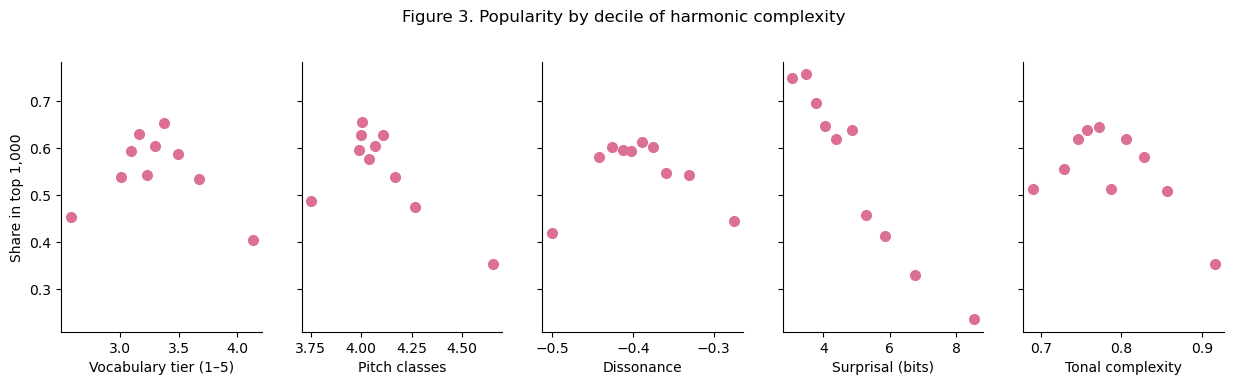

In [16]:
y = "log_listeners" if "log_listeners" in tune_level.columns else "js_top1000"

fig, axes = plt.subplots(1, 5, figsize=(15, 3.5), sharey=True)
for ax, m in zip(axes, measures):
    bins = pd.qcut(tune_level[m].rank(method="first"), 10, labels=False)   # Rank first so ties don't break qcut
    binned = tune_level.groupby(bins).agg(x=(m, "mean"), y=(y, "mean"))
    ax.plot(binned["x"], binned["y"], color="palevioletred", marker="o", markersize=7, linewidth=0)
    ax.set_xlabel(measure_labels[m])
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Share in top 1,000" if y == "js_top1000" else "Mean log(total listeners)")
fig.suptitle("Figure 3. Popularity by decile of harmonic complexity", y=1.03)
plt.savefig(output_dir + "fig3_binscatter_rq2.png", dpi=200, bbox_inches="tight")
plt.show()

### 5. Within-tune version: recordings of "Autumn Leaves"
Comparing *different tunes* mixes up harmony with everything else about the tune (melody, lyrics, era, origin). One way around that is to hold the tune fixed: compare **different recordings of the same tune** that harmonize it differently (e.g. a straight reading vs. a heavily reharmonized one).

**The catch:** the iRb corpus has one chart per *tune*, not per *recording*. To know what chords each recording uses, someone has to listen and transcribe them. So this section does three things:
1. Pulls the jazz recordings of "Autumn Leaves" from Last.fm (listeners, plays, and the artist's overall listeners as a fame control).
2. Writes a **coding sheet** (`rawdata/autumnleaves_coding.csv`) with an empty `chords_A_section` column for me to fill in by ear. The first row is the iRb lead sheet, as an example of the format.
3. Once rows are filled in, computes the same complexity measures for each recording and regresses log(listeners) on complexity, controlling for log(artist listeners).

**Coding format:** the chords of the **first A section (8 bars)** as you hear them, space-separated, one symbol per chord change, in normal lead-sheet spelling: `Cm7 F7 Bbmaj7 Ebmaj7 Am7b5 D7b9 Gm6`. Allowed: `m`/`-` for minor, `maj7`, `m7b5`/`ø7`, `dim7`/`°7`, `7b9`, `7#11`, `13`, `7alt`, `sus4`, slash bass (`D7/F#`). Write a 6/9 chord as `69`.

Even within one tune this still isn't causal: artists who reharmonize heavily may differ in other ways (tempo, instrumentation, label promotion), and I'll only have a few dozen recordings. But it does get rid of the "different tunes" confound.

In [17]:
AL_MAX_PAGES = 10   # Search deeper for this one tune

al_coding_path = rawdata_dir + "autumnleaves_coding.csv"
al_tune = tune_level[tune_level["tune_id"] == "autumnleaves"].copy()
al_tune["tune_id"] = "autumnleaves_deep"   # Separate cache key from the main run

if LASTFM_API_KEY != "" and not os.path.exists(al_coding_path):
    MAX_PAGES_main, MAX_PAGES = MAX_PAGES, AL_MAX_PAGES
    PLAYCOUNT_TOP_N_main, PLAYCOUNT_TOP_N = PLAYCOUNT_TOP_N, 1000   # Get play counts for every Autumn Leaves recording
    al_recordings = run_lastfm_pipeline(al_tune)
    MAX_PAGES, PLAYCOUNT_TOP_N = MAX_PAGES_main, PLAYCOUNT_TOP_N_main

    al_recordings = al_recordings.sort_values("listeners", ascending=False)
    al_sheet = al_recordings[["artist", "track", "listeners", "playcount", "artist_listeners"]].copy()
    al_sheet["lastfm_url"] = ["https://www.last.fm/music/" + urllib.parse.quote(a.replace(" ", "+"), safe="+") + "/_/" + urllib.parse.quote(t.replace(" ", "+"), safe="+")
                              for a, t in zip(al_sheet["artist"], al_sheet["track"])]
    al_sheet["chords_A_section"] = ""
    al_sheet["notes"] = ""

    # First row = the iRb lead sheet, as an example of the coding format (no listener data, so it's left out of the regression)
    example = pd.DataFrame([{"artist": "iRb lead sheet (example row)", "track": "Autumn Leaves",
                             "chords_A_section": "Cm7 F7 Bbmaj7 Ebmaj7 Am7b5 D7b13 Gm6"}])
    pd.concat([example, al_sheet]).to_csv(al_coding_path, index=False)   # Only written once, so filled-in codes never get overwritten
    print("Wrote coding sheet with " + str(len(al_sheet)) + " recordings to " + al_coding_path)
elif os.path.exists(al_coding_path):
    print("Coding sheet already exists: " + al_coding_path)
else:
    print("No API key yet: paste it into the LASTFM_API_KEY cell in Section 3.")

No API key yet: paste it into the LASTFM_API_KEY cell in Section 3.


**Chord functions from RQ1.** To score the Autumn Leaves recordings, I need the same chord parser and complexity functions as the RQ1 notebook. They're copied below so this notebook runs on its own. **If I change them in RQ1, I need to change them here too.**

In [18]:
# Copied from jazzchords_pan_rq1_complexity.ipynb (Sections 2 and 4); keep in sync

NOTE_PCS = {"C": 0, "D": 2, "E": 4, "F": 5, "G": 7, "A": 9, "B": 11}

def note_to_pc(note):
    # "B-" → 10, "F#" → 6
    return (NOTE_PCS[note[0]] + note.count("#") - note.count("-")) % 12

# Base chord qualities, as semitones above the root. Order matters: longer spellings come first so "min7" is checked before "min".
BASE_QUALITIES = [
    ("min:maj7", [0, 3, 7, 11]),
    ("min69",    [0, 3, 7, 9, 2]),
    ("min11",    [0, 3, 7, 10, 2, 5]),
    ("min9",     [0, 3, 7, 10, 2]),
    ("min7b5",   [0, 3, 6, 10]),       # Same thing as half-diminished
    ("min7",     [0, 3, 7, 10]),
    ("minb6",    [0, 3, 7, 8]),
    ("min6",     [0, 3, 7, 9]),
    ("min",      [0, 3, 7]),
    ("maj9",     [0, 4, 7, 11, 2]),
    ("maj7",     [0, 4, 7, 11]),
    ("maj",      [0, 4, 7]),
    ("^9",       [0, 4, 7, 11, 2]),    # ^ is iReal shorthand for maj7
    ("^",        [0, 4, 7, 11]),
    ("h7",       [0, 3, 6, 10]),       # Half-diminished (ø7)
    ("h",        [0, 3, 6, 10]),
    ("dim7",     [0, 3, 6, 9]),
    ("o7",       [0, 3, 6, 9]),        # Diminished 7th (°7)
    ("o",        [0, 3, 6]),           # Diminished triad
    ("+",        [0, 4, 8]),           # Augmented triad
    ("69",       [0, 4, 7, 9, 2]),
    ("6",        [0, 4, 7, 9]),
    ("13",       [0, 4, 7, 10, 2, 9]),
    ("11",       [0, 7, 10, 2, 5]),
    ("9",        [0, 4, 7, 10, 2]),
    ("7",        [0, 4, 7, 10]),       # Dominant 7th
    ("add9",     [0, 4, 7, 2]),
    ("sus",      [0, 5, 7]),
    ("",         [0, 4, 7]),           # Plain major triad
]

# Modifiers that add a note (semitones above root)
ADDED_TONES = {"b9": 1, "9": 2, "#9": 3, "11": 5, "#11": 6, "b13": 8, "13": 9, "6": 9, "b6": 8, "add9": 2, "add3": 4}
ALTERATIONS = {"b9", "#9", "#11", "b13", "#5", "+", "b5", "alt"}

def parse_chord(token):
    # Split "2.C7b9/G" into duration ("2.") and symbol ("C7b9/G")
    m = re.match(r"^(\d+)(\.*)(.*)$", token)
    if not m:
        return None
    duration = (1 / int(m.group(1))) * (1.5 ** len(m.group(2)))   # In whole notes; each dot = x1.5
    symbol = re.sub(r"\(.*?\)", "", m.group(3))                     # Drop alternate chords in parentheses
    symbol = symbol.replace(";", "").replace("*", "")               # Drop stray characters
    if symbol in ("r", ""):
        return None                                                 # Rest / no chord

    # Root
    m = re.match(r"^([A-G][#-]*)(.*)$", symbol)
    if not m:
        return None
    root = note_to_pc(m.group(1))

    # Quality and slash bass
    quality, _, bass = m.group(2).partition("/")
    quality = re.sub(r"(?<!s)u", "sus", quality.lstrip(":"))        # A few charts write "7u" for 7sus

    for spelling, intervals in BASE_QUALITIES:
        if quality.startswith(spelling):
            base = spelling
            rest = quality[len(spelling):]
            tones = set(intervals)
            break

    # Modifiers
    mods = re.findall(r"sus|add\d+|alt|[b#]\d+|\+|69|\d+", rest)
    if "".join(mods) != rest:
        return None                                                 # Couldn't read part of the symbol
    for mod in mods:
        if mod == "sus":
            tones = (tones - {3, 4}) | {5}
        elif mod == "alt":
            tones = (tones - {7}) | {1, 3, 8}
        elif mod == "b5":
            tones = (tones - {7}) | {6}
        elif mod in ("#5", "+"):
            tones = (tones - {7}) | {8}
        elif mod == "69":
            tones = tones | {9, 2}
        elif mod in ADDED_TONES:
            tones = tones | {ADDED_TONES[mod]}
        else:
            return None

    pcs = {(root + t) % 12 for t in tones}
    bass_pc = None
    if bass:
        if not re.match(r"^[A-G][#-]*$", bass):
            return None
        bass_pc = note_to_pc(bass)
        pcs.add(bass_pc)

    return {"duration": duration, "root": root, "quality": quality, "base": base,
            "mods": mods, "bass": bass_pc, "pcs": frozenset(pcs)}

def chord_family(base, mods):
    if any(m in ALTERATIONS for m in mods):
        return "Altered"
    if base in ("min9", "min11", "maj9", "^9", "13", "11", "9", "add9", "69", "min69") or any(m in ("9", "11", "13", "add9", "69", "add3") for m in mods):
        return "Extended"
    if base in ("", "maj", "min"):
        return "Dim/aug/sus triad" if "sus" in mods else "Maj/min triad"
    if base in ("o", "+", "sus"):
        return "Dim/aug/sus triad"
    if base in ("6", "min6", "minb6") or "6" in mods or "b6" in mods:
        return "Sixth"
    if base in ("h7", "h", "min7b5"):
        return "Half-dim 7th"
    if base in ("o7", "dim7"):
        return "Dim 7th"
    if base == "min:maj7":
        return "Min-maj 7th"
    return "Seventh"   # maj7, min7, 7, 7sus

TIER = {"Maj/min triad": 1, "Dim/aug/sus triad": 2, "Seventh": 3,
        "Sixth": 4, "Half-dim 7th": 4, "Dim 7th": 4, "Min-maj 7th": 4,
        "Extended": 5, "Altered": 5}

# Huron (1994) consonance values for interval classes 1–6 (ic1 = minor 2nd/major 7th, ..., ic6 = tritone)
HURON = {1: -1.428, 2: -0.582, 3: 0.594, 4: 0.386, 5: 1.240, 6: -0.453}

def dissonance(pcs):
    pair_values = []
    for a, b in combinations(sorted(pcs), 2):     # Every pair of notes in the chord
        ic = min((a - b) % 12, (b - a) % 12)      # Interval class: 1–6
        pair_values.append(HURON[ic])
    return -np.mean(pair_values)                  # Negative so that higher = more dissonant

def tonal_complexity(chroma):
    # chroma = length-12 array of how much each pitch class (C, C#, ..., B) is used
    chroma = np.asarray(chroma, dtype=float)
    angles = 2 * np.pi * 7 * np.arange(12) / 12             # Multiplying by 7 reorders pitch classes along the circle of fifths
    r = np.abs(np.sum(chroma * np.exp(1j * angles))) / chroma.sum()
    return np.sqrt(1 - r)

In [19]:
# Convert normal lead-sheet symbols to iRb spelling so parse_chord() can read them: "Bbmaj7" → "1B-:maj7", "Am7b5" → "1Ah7"
def leadsheet_to_irb(symbol):
    m = re.match(r"^([A-G])([b#]?)([^/]*)(?:/([A-G])([b#]?))?$", symbol.strip())
    if not m:
        return None
    root = m.group(1) + m.group(2).replace("b", "-")
    q = m.group(3).replace("ø7", "h7").replace("ø", "h7").replace("°7", "o7").replace("°", "o")
    q = q.replace("dim7", "o7").replace("dim", "o").replace("aug", "+").replace("sus4", "sus")
    q = re.sub(r"^(\^|Δ)7?", "maj7", q)                     # Eb^7 / EbΔ7 → maj7 (and ^9 → maj7 + 9)
    q = re.sub(r"^(m|-|min)7b5", "h7", q)
    q = re.sub(r"^(mMaj7|mmaj7|m\(maj7\)|-maj7|minmaj7)", "min:maj7", q)
    if q.startswith("maj") or q.startswith("min:maj7"):
        q = ":" + q
    elif re.match(r"^(min|m|-)", q):
        q = ":min" + re.sub(r"^(min|m|-)", "", q)
    bass = "/" + m.group(4) + m.group(5).replace("b", "-") if m.group(4) else ""
    return "1" + root + q + bass   # "1" = placeholder duration, so every chord counts equally

# Surprisal of a transition using the full-corpus counts from the RQ1 notebook (loaded in Section 1)
def corpus_surprisal(context, outcome):
    return -np.log2((pair_all.get((context, outcome), 0) + K) / (ctx_all.get(context, 0) + K * V))

def measures_for_sequence(chord_string):
    parsed_seq = [parse_chord(leadsheet_to_irb(s) or "") for s in str(chord_string).split()]
    if len(parsed_seq) == 0 or any(c is None for c in parsed_seq):
        return pd.Series({m: np.nan for m in measures})   # Typo somewhere in the row
    families = [chord_family(c["base"], c["mods"]) for c in parsed_seq]
    surprisals = [corpus_surprisal(prev["quality"], str((c["root"] - prev["root"]) % 12) + "|" + c["quality"])
                  for prev, c in zip(parsed_seq[:-1], parsed_seq[1:])]
    chroma = np.zeros(12)
    for c in parsed_seq:
        chroma[list(c["pcs"])] += 1
    return pd.Series({"tier": np.mean([TIER[f] for f in families]),
                      "n_pcs": np.mean([len(c["pcs"]) for c in parsed_seq]),
                      "dissonance": np.mean([dissonance(c["pcs"]) for c in parsed_seq]),
                      "surprisal": np.mean(surprisals) if surprisals else np.nan,
                      "tonal_complexity": tonal_complexity(chroma)})

# Checks: the iRb Autumn Leaves A section
measures_for_sequence("Cm7 F7 Bbmaj7 Ebmaj7 Am7b5 D7b13 Gm6")

tier                3.571429
n_pcs               4.142857
dissonance         -0.332610
surprisal           3.621344
tonal_complexity    0.760284
dtype: float64

In [20]:
# Analysis: runs once at least 10 recordings have been coded
if os.path.exists(al_coding_path):
    al = pd.read_csv(al_coding_path)
    al = al[al["chords_A_section"].notna() & al["listeners"].notna()].copy()
    if len(al) < 10:
        print("Only " + str(len(al)) + " recordings coded so far: code at least 10 (ideally 30+) before running the regressions.")
    else:
        al = pd.concat([al, al["chords_A_section"].apply(measures_for_sequence)], axis=1)
        display(al.loc[al[measures].isna().any(axis=1), ["artist", "chords_A_section"]])   # Rows with a chord symbol that didn't parse
        al = al.dropna(subset=measures)
        al["log_listeners"] = np.log(al["listeners"])
        al["log_artist_listeners"] = np.log(al["artist_listeners"])
        for m in measures:
            al["z_" + m] = (al[m] - al[m].mean()) / al[m].std()

        table5 = pd.DataFrame(index=[measure_labels[m] for m in measures], columns=["Coef. on complexity (SE)", "N"])
        for m in measures:
            fit = smf.ols("log_listeners ~ z_" + m + " + log_artist_listeners", data=al).fit(cov_type="HC1")
            stars = "***" if fit.pvalues["z_" + m] < 0.01 else "**" if fit.pvalues["z_" + m] < 0.05 else "*" if fit.pvalues["z_" + m] < 0.1 else ""
            table5.loc[measure_labels[m]] = [f"{fit.params['z_' + m]:.3f}{stars} ({fit.bse['z_' + m]:.3f})", int(fit.nobs)]
        table5.to_csv(output_dir + "table5_autumnleaves_within_tune.csv")
        display(table5)

### Conclusion (preliminary: this notebook is incomplete):
**So far (JazzStandards.com outcomes only):** Tunes with more surprising progressions are less likely to be in the top 1,000 (−5.4 percentage points per SD, controlling for era, key, and meter). Among ranked tunes, tier, pitch classes, and dissonance have a significant inverted U with rank (Table 4b): tunes in the middle of the complexity range get recorded by the most artists. That matches the "Wundt curve" idea, but it's an association, not a causal effect. One big caveat is that newer tunes have had less time to be recorded *and* are more surprising, and the era controls only partly deal with that.

**To finish this notebook:**
1. Get a Last.fm API key, run the pilot, then the full run overnight (~2–4 hours), and re-run Section 4 so Table 4 includes the listening outcomes.
2. Code the Autumn Leaves recordings in `rawdata/autumnleaves_coding.csv` for the within-tune version (Section 5).
3. Think about the "newer tunes have had less time" problem, e.g. by limiting the sample to tunes written before a cutoff year.